In [1]:
# ============================================================
# STEP 01.1 — LOAD AND INSPECT EMBEDDINGS
# ============================================================
# Objective:
# Load the frozen 32D embeddings and corresponding labels
# for Genetic, Behavioral, and Environmental modalities.
#
# This is READ-ONLY analysis.
# No embeddings are modified.
# ============================================================

import numpy as np
import pandas as pd
from pathlib import Path

print("=" * 100)
print("STEP 01.1 — LOAD AND INSPECT EMBEDDINGS")
print("=" * 100)


# ------------------------------------------------------------
# Resolve Project Root
# ------------------------------------------------------------

NOTEBOOK_DIR = Path.cwd()

PROJECT_ROOT = NOTEBOOK_DIR

while PROJECT_ROOT.name != "GAN-Enhanced-Multimodal-ASD-Screening":
    if PROJECT_ROOT.parent == PROJECT_ROOT:
        raise RuntimeError(
            "Project root 'GAN-Enhanced-Multimodal-ASD-Screening' "
            "could not be located."
        )
    PROJECT_ROOT = PROJECT_ROOT.parent


print(f"\nProject Root:\n{PROJECT_ROOT}")


# ------------------------------------------------------------
# Define Frozen Baseline Embedding Paths
# ------------------------------------------------------------

FUSION_DIR = PROJECT_ROOT / "05_multimodal_fusion"

paths = {
    "Genetic": {
        "embedding": FUSION_DIR / "genetic_32d_normalized.npy",
        "targets": FUSION_DIR / "genetic_targets.npy"
    },

    "Behavioral": {
        "embedding": FUSION_DIR / "behavioral_32d_normalized.npy",
        "targets": FUSION_DIR / "behavioral_targets.npy"
    },

    "Environmental": {
        "embedding": FUSION_DIR / "environmental_32d_normalized.npy",
        "targets": FUSION_DIR / "environmental_targets.npy"
    }
}


# ------------------------------------------------------------
# Load Embeddings and Labels
# ------------------------------------------------------------

data = {}

print("\n" + "=" * 100)
print("LOADING FROZEN BASELINE REPRESENTATIONS")
print("=" * 100)

for modality, file_paths in paths.items():

    embedding_path = file_paths["embedding"]
    target_path = file_paths["targets"]

    if not embedding_path.exists():
        raise FileNotFoundError(
            f"{modality} embedding not found:\n{embedding_path}"
        )

    if not target_path.exists():
        raise FileNotFoundError(
            f"{modality} targets not found:\n{target_path}"
        )

    X = np.load(embedding_path)
    y = np.load(target_path)

    data[modality] = {
        "X": X,
        "y": y
    }

    print(f"\n{modality.upper()}")
    print("-" * 60)
    print(f"Embedding file : {embedding_path.name}")
    print(f"Target file    : {target_path.name}")
    print(f"Embedding shape: {X.shape}")
    print(f"Label shape    : {y.shape}")
    print(f"Embedding dtype: {X.dtype}")
    print(f"Label dtype    : {y.dtype}")
    print(f"Unique labels  : {np.unique(y)}")


# ------------------------------------------------------------
# Verify Structural Compatibility
# ------------------------------------------------------------

print("\n" + "=" * 100)
print("STRUCTURAL VERIFICATION")
print("=" * 100)

summary_records = []

for modality, values in data.items():

    X = values["X"]
    y = values["y"]

    sample_match = X.shape[0] == y.shape[0]

    is_32d = (
        X.ndim == 2
        and X.shape[1] == 32
    )

    unique_labels, counts = np.unique(y, return_counts=True)

    class_distribution = {
        int(label): int(count)
        for label, count in zip(unique_labels, counts)
    }

    summary_records.append({
        "Modality": modality,
        "Samples": X.shape[0],
        "Embedding Dimension": X.shape[1] if X.ndim == 2 else "INVALID",
        "Embedding Shape": str(X.shape),
        "Label Shape": str(y.shape),
        "Sample-Label Match": sample_match,
        "Is 32D": is_32d,
        "Unique Labels": str(unique_labels.tolist()),
        "Class Distribution": str(class_distribution)
    })


summary_df = pd.DataFrame(summary_records)

print("\n")
display(summary_df)


# ------------------------------------------------------------
# Final Validation
# ------------------------------------------------------------

all_valid = (
    summary_df["Sample-Label Match"].all()
    and summary_df["Is 32D"].all()
)

print("\n" + "=" * 100)

if all_valid:
    print("✓ STEP 01.1 COMPLETED SUCCESSFULLY")
    print("✓ All modalities have valid sample-label correspondence")
    print("✓ All embeddings are confirmed as 32-dimensional")
    print("✓ Ready for Step 01.2 — Representation Statistics")
else:
    print("⚠ VALIDATION ISSUE DETECTED")
    print("Do not proceed until structural inconsistencies are resolved.")

print("=" * 100)


# ------------------------------------------------------------
# Save Inspection Report
# ------------------------------------------------------------

REPORT_DIR = (
    PROJECT_ROOT
    / "06_cross_modal_learning"
    / "01_embedding_analysis"
    / "reports"
)

REPORT_DIR.mkdir(parents=True, exist_ok=True)

report_path = REPORT_DIR / "01_01_embedding_inspection.csv"

summary_df.to_csv(report_path, index=False)

print(f"\nReport saved to:\n{report_path}")

STEP 01.1 — LOAD AND INSPECT EMBEDDINGS

Project Root:
C:\Users\shasw\Documents\GitHub\GAN-Enhanced-Multimodal-ASD-Screening

LOADING FROZEN BASELINE REPRESENTATIONS

GENETIC
------------------------------------------------------------
Embedding file : genetic_32d_normalized.npy
Target file    : genetic_targets.npy
Embedding shape: (116, 32)
Label shape    : (116,)
Embedding dtype: float32
Label dtype    : int64
Unique labels  : [0 1]

BEHAVIORAL
------------------------------------------------------------
Embedding file : behavioral_32d_normalized.npy
Target file    : behavioral_targets.npy
Embedding shape: (880, 32)
Label shape    : (880,)
Embedding dtype: float32
Label dtype    : int64
Unique labels  : [0 1]

ENVIRONMENTAL
------------------------------------------------------------
Embedding file : environmental_32d_normalized.npy
Target file    : environmental_targets.npy
Embedding shape: (47768, 32)
Label shape    : (47768,)
Embedding dtype: float32
Label dtype    : int64
Unique 

,Modality,Samples,Embedding Dimension,Embedding Shape,Label Shape,Sample-Label Match,Is 32D,Unique Labels,Class Distribution
0,Genetic,116,32,"(116, 32)","(116,)",True,True,"[0, 1]","{0: 29, 1: 87}"
1,Behavioral,880,32,"(880, 32)","(880,)",True,True,"[0, 1]","{0: 439, 1: 441}"
2,Environmental,47768,32,"(47768, 32)","(47768,)",True,True,"[0, 1]","{0: 45650, 1: 2118}"



✓ STEP 01.1 COMPLETED SUCCESSFULLY
✓ All modalities have valid sample-label correspondence
✓ All embeddings are confirmed as 32-dimensional
✓ Ready for Step 01.2 — Representation Statistics

Report saved to:
C:\Users\shasw\Documents\GitHub\GAN-Enhanced-Multimodal-ASD-Screening\06_cross_modal_learning\01_embedding_analysis\reports\01_01_embedding_inspection.csv


In [2]:
# ============================================================
# STEP 01.2 — REPRESENTATION STATISTICS
# ============================================================
# Objective:
# Audit the numerical properties of the frozen 32D embeddings.
#
# Statistics calculated:
# - Mean
# - Standard Deviation
# - Minimum
# - Maximum
# - Variance
# - L2 Norm
#
# Both global and per-dimension statistics are generated.
# ============================================================

import numpy as np
import pandas as pd

print("=" * 100)
print("STEP 01.2 — REPRESENTATION STATISTICS")
print("=" * 100)


# ------------------------------------------------------------
# Storage
# ------------------------------------------------------------

global_statistics = []
dimension_statistics = []


# ------------------------------------------------------------
# Calculate Statistics for Each Modality
# ------------------------------------------------------------

for modality, values in data.items():

    X = values["X"]

    # --------------------------------------------------------
    # Global Statistics
    # --------------------------------------------------------

    global_mean = np.mean(X)
    global_std = np.std(X)
    global_min = np.min(X)
    global_max = np.max(X)
    global_variance = np.var(X)

    # L2 norm for each sample
    sample_norms = np.linalg.norm(X, axis=1)

    avg_l2_norm = np.mean(sample_norms)
    min_l2_norm = np.min(sample_norms)
    max_l2_norm = np.max(sample_norms)
    std_l2_norm = np.std(sample_norms)


    global_statistics.append({
        "Modality": modality,
        "Samples": X.shape[0],
        "Dimensions": X.shape[1],
        "Mean": float(global_mean),
        "Std": float(global_std),
        "Min": float(global_min),
        "Max": float(global_max),
        "Variance": float(global_variance),
        "Avg L2 Norm": float(avg_l2_norm),
        "Min L2 Norm": float(min_l2_norm),
        "Max L2 Norm": float(max_l2_norm),
        "Std L2 Norm": float(std_l2_norm)
    })


    # --------------------------------------------------------
    # Per-Dimension Statistics
    # --------------------------------------------------------

    for dimension in range(X.shape[1]):

        dimension_values = X[:, dimension]

        dimension_statistics.append({
            "Modality": modality,
            "Dimension": dimension,
            "Mean": float(np.mean(dimension_values)),
            "Std": float(np.std(dimension_values)),
            "Min": float(np.min(dimension_values)),
            "Max": float(np.max(dimension_values)),
            "Variance": float(np.var(dimension_values))
        })


# ------------------------------------------------------------
# Create DataFrames
# ------------------------------------------------------------

global_stats_df = pd.DataFrame(global_statistics)

dimension_stats_df = pd.DataFrame(dimension_statistics)


# ------------------------------------------------------------
# Display Global Statistics
# ------------------------------------------------------------

print("\nGLOBAL REPRESENTATION STATISTICS")
print("-" * 100)

display(
    global_stats_df.style.format({
        "Mean": "{:.6f}",
        "Std": "{:.6f}",
        "Min": "{:.6f}",
        "Max": "{:.6f}",
        "Variance": "{:.6f}",
        "Avg L2 Norm": "{:.6f}",
        "Min L2 Norm": "{:.6f}",
        "Max L2 Norm": "{:.6f}",
        "Std L2 Norm": "{:.6f}"
    })
)


# ------------------------------------------------------------
# Print Interpretation-Friendly Summary
# ------------------------------------------------------------

print("\n" + "=" * 100)
print("L2 NORM SUMMARY")
print("=" * 100)

for _, row in global_stats_df.iterrows():

    print(f"\n{row['Modality'].upper()}")
    print(f"  Mean value      : {row['Mean']:.6f}")
    print(f"  Standard dev    : {row['Std']:.6f}")
    print(f"  Value range     : [{row['Min']:.6f}, {row['Max']:.6f}]")
    print(f"  Variance        : {row['Variance']:.6f}")
    print(f"  Average L2 norm : {row['Avg L2 Norm']:.6f}")
    print(
        f"  L2 norm range   : "
        f"[{row['Min L2 Norm']:.6f}, "
        f"{row['Max L2 Norm']:.6f}]"
    )


# ------------------------------------------------------------
# Save Reports
# ------------------------------------------------------------

REPORT_DIR = (
    PROJECT_ROOT
    / "06_cross_modal_learning"
    / "01_embedding_analysis"
    / "reports"
)

global_report_path = (
    REPORT_DIR
    / "01_02_global_representation_statistics.csv"
)

dimension_report_path = (
    REPORT_DIR
    / "01_02_per_dimension_statistics.csv"
)

global_stats_df.to_csv(
    global_report_path,
    index=False
)

dimension_stats_df.to_csv(
    dimension_report_path,
    index=False
)


print("\n" + "=" * 100)
print("✓ STEP 01.2 COMPLETED")
print("=" * 100)

print(f"\nGlobal statistics saved:\n{global_report_path}")
print(f"\nPer-dimension statistics saved:\n{dimension_report_path}")

print("\nNext Step:")
print("01.3 — Distribution Comparison")

STEP 01.2 — REPRESENTATION STATISTICS

GLOBAL REPRESENTATION STATISTICS
----------------------------------------------------------------------------------------------------


,Modality,Samples,Dimensions,Mean,Std,Min,Max,Variance,Avg L2 Norm,Min L2 Norm,Max L2 Norm,Std L2 Norm
0,Genetic,116,32,-0.000000,1.000000,-3.779795,3.284362,1.000000,5.563721,3.303348,8.820985,1.022256
1,Behavioral,880,32,0.000000,1.000000,-4.194437,4.268354,1.000000,5.633084,3.784771,7.305407,0.518040
2,Environmental,47768,32,-0.000000,1.000000,-6.605281,7.128363,1.000000,5.450624,2.752760,14.868624,1.513507



L2 NORM SUMMARY

GENETIC
  Mean value      : -0.000000
  Standard dev    : 1.000000
  Value range     : [-3.779795, 3.284362]
  Variance        : 1.000000
  Average L2 norm : 5.563721
  L2 norm range   : [3.303348, 8.820985]

BEHAVIORAL
  Mean value      : 0.000000
  Standard dev    : 1.000000
  Value range     : [-4.194437, 4.268354]
  Variance        : 1.000000
  Average L2 norm : 5.633084
  L2 norm range   : [3.784771, 7.305407]

ENVIRONMENTAL
  Mean value      : -0.000000
  Standard dev    : 1.000000
  Value range     : [-6.605281, 7.128363]
  Variance        : 1.000000
  Average L2 norm : 5.450624
  L2 norm range   : [2.752760, 14.868624]

✓ STEP 01.2 COMPLETED

Global statistics saved:
C:\Users\shasw\Documents\GitHub\GAN-Enhanced-Multimodal-ASD-Screening\06_cross_modal_learning\01_embedding_analysis\reports\01_02_global_representation_statistics.csv

Per-dimension statistics saved:
C:\Users\shasw\Documents\GitHub\GAN-Enhanced-Multimodal-ASD-Screening\06_cross_modal_learning\01_e

In [4]:
%pip install matplotlib

  Using cached contourpy-1.3.3-cp314-cp314-win_amd64.whl.metadata (5.5 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached pyparsing-3.3.2-py3-none-any.whl.metadata (5.8 kB)
   ---------------------------------------- 0.0/9.5 MB ? eta -:--:--
   --- ------------------------------------ 0.8/9.5 MB 4.4 MB/s eta 0:00:02
   -------- ------------------------------- 2.1/9.5 MB 5.3 MB/s eta 0:00:02
   -------------- ------------------------- 3.4/9.5 MB 5.5 MB/s eta 0:00:02
   ------------------ --------------------- 4.5/9.5 MB 5.4 MB/s eta 0:00:01
   ------------------------- -------------- 6.0/9.5 MB 5.9 MB/s eta 0:00:01
   ------------------------------ --------- 7.3/9.5 MB 6.0 MB/s eta 0:00:01
   ------------------------------------- -- 8.9/9.5 MB 6.0 MB/s eta 0:00:01
   ---------------------------------------- 9.5/9.5 MB 5.9 MB/s  0:00:01
Using cached contourpy-1.3.3-cp314-cp314-win_amd64.whl (232 kB)
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
   -

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


In [1]:
import matplotlib.pyplot as plt

print("Matplotlib installed successfully!")

Matplotlib installed successfully!


In [3]:
# ============================================================
# RELOAD PROJECT CONTEXT AFTER KERNEL RESTART
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd

# Resolve project root
PROJECT_ROOT = Path.cwd()

# If notebook is inside:
# 06_cross_modal_learning/01_embedding_analysis/notebooks
# go back 3 levels to project root
for _ in range(3):
    PROJECT_ROOT = PROJECT_ROOT.parent

print("Current working directory:")
print(Path.cwd())

print("\nResolved PROJECT_ROOT:")
print(PROJECT_ROOT)

print("\nProject root exists:", PROJECT_ROOT.exists())


# ============================================================
# RELOAD FROZEN 32D EMBEDDINGS
# ============================================================

FUSION_DIR = PROJECT_ROOT / "05_multimodal_fusion"

data = {
    "Genetic": {
        "X": np.load(FUSION_DIR / "genetic_32d_normalized.npy"),
        "y": np.load(FUSION_DIR / "genetic_targets.npy")
    },
    "Behavioral": {
        "X": np.load(FUSION_DIR / "behavioral_32d_normalized.npy"),
        "y": np.load(FUSION_DIR / "behavioral_targets.npy")
    },
    "Environmental": {
        "X": np.load(FUSION_DIR / "environmental_32d_normalized.npy"),
        "y": np.load(FUSION_DIR / "environmental_targets.npy")
    }
}

print("\nEmbeddings reloaded successfully:\n")

for modality, values in data.items():
    print(
        f"{modality:15} "
        f"Embeddings: {values['X'].shape} | "
        f"Labels: {values['y'].shape}"
    )

print("\n✓ PROJECT CONTEXT RESTORED")

Current working directory:
C:\Users\shasw\Documents\GitHub\GAN-Enhanced-Multimodal-ASD-Screening\06_cross_modal_learning\01_embedding_analysis\notebooks

Resolved PROJECT_ROOT:
C:\Users\shasw\Documents\GitHub\GAN-Enhanced-Multimodal-ASD-Screening

Project root exists: True

Embeddings reloaded successfully:

Genetic         Embeddings: (116, 32) | Labels: (116,)
Behavioral      Embeddings: (880, 32) | Labels: (880,)
Environmental   Embeddings: (47768, 32) | Labels: (47768,)

✓ PROJECT CONTEXT RESTORED


STEP 01.3 — EMBEDDING DISTRIBUTION COMPARISON


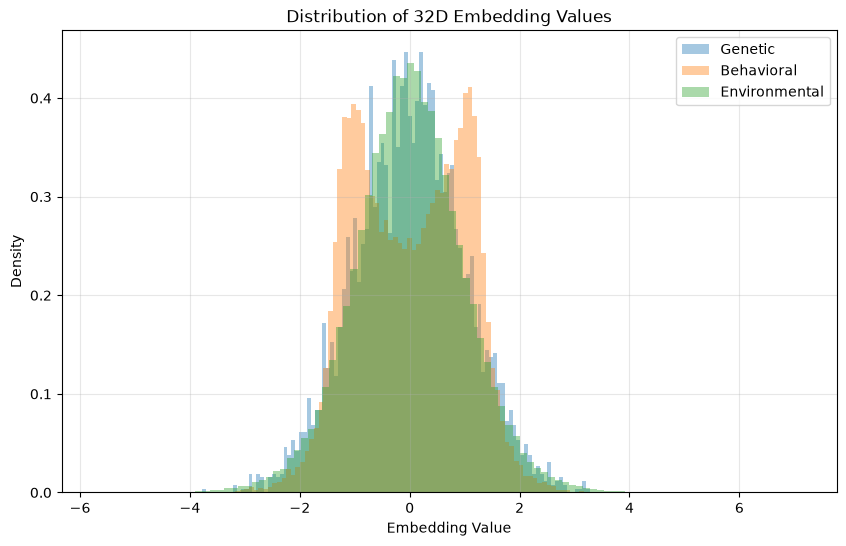


Saved: C:\Users\shasw\Documents\GitHub\GAN-Enhanced-Multimodal-ASD-Screening\06_cross_modal_learning\01_embedding_analysis\figures\01_03_embedding_value_distribution.png


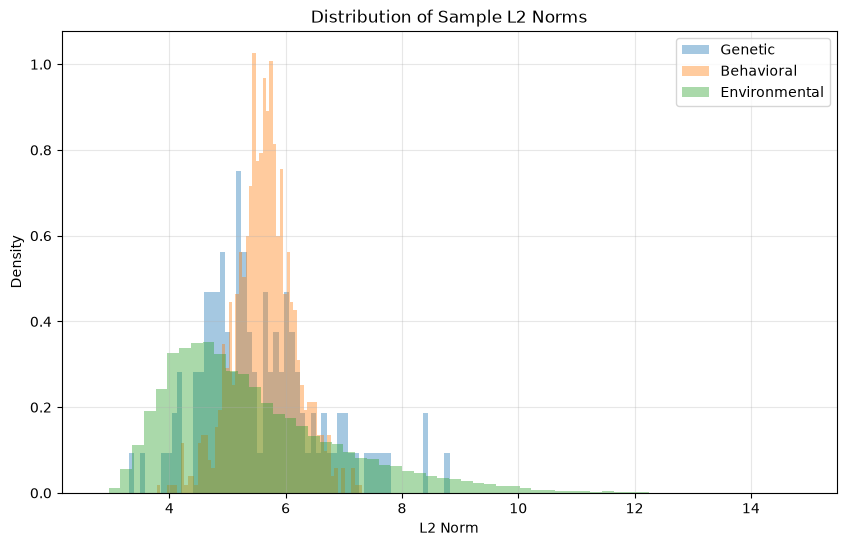

Saved: C:\Users\shasw\Documents\GitHub\GAN-Enhanced-Multimodal-ASD-Screening\06_cross_modal_learning\01_embedding_analysis\figures\01_03_l2_norm_distribution.png


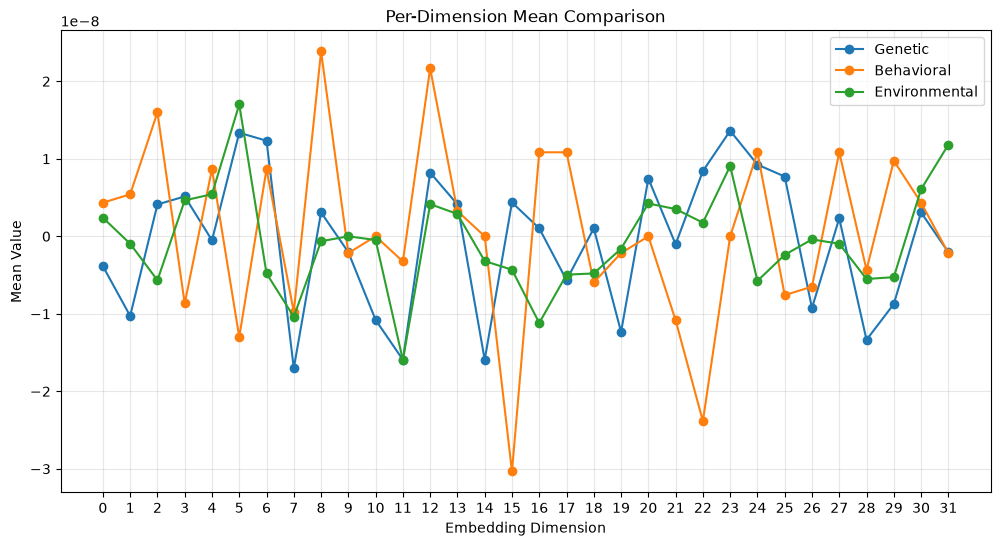

Saved: C:\Users\shasw\Documents\GitHub\GAN-Enhanced-Multimodal-ASD-Screening\06_cross_modal_learning\01_embedding_analysis\figures\01_03_per_dimension_means.png


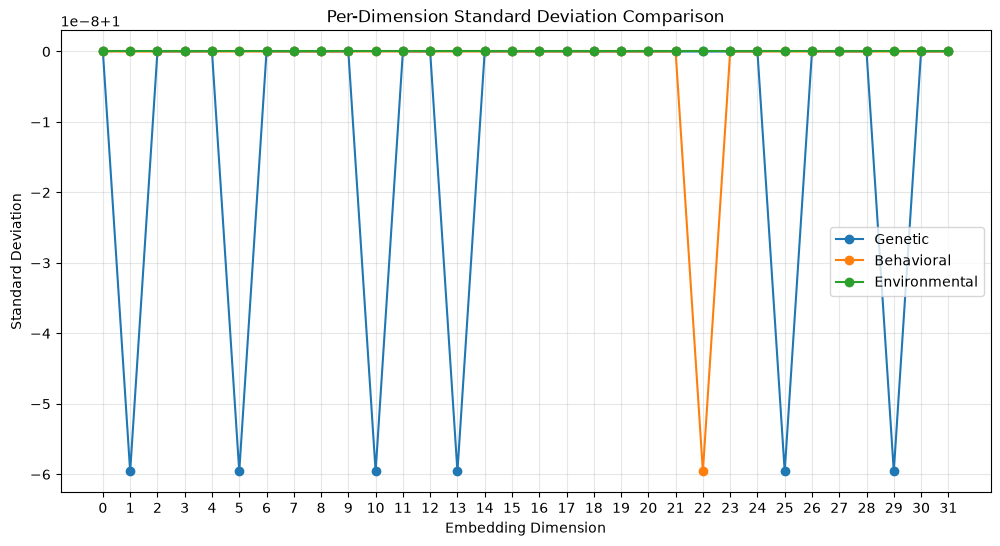

Saved: C:\Users\shasw\Documents\GitHub\GAN-Enhanced-Multimodal-ASD-Screening\06_cross_modal_learning\01_embedding_analysis\figures\01_03_per_dimension_std.png

DISTRIBUTION SUMMARY


,Modality,Embedding Mean,Embedding Std,Embedding Median,Embedding Q1,Embedding Q3,L2 Norm Mean,L2 Norm Std,L2 Norm Median
0,Genetic,-0.000000,1.000000,0.009575,-0.682348,0.675048,5.563721,1.022256,5.343289
1,Behavioral,-0.000000,1.000000,0.017969,-0.872758,0.863998,5.633084,0.518040,5.634198
2,Environmental,-0.000000,1.000000,-0.006042,-0.634156,0.634193,5.450624,1.513507,5.090984



✓ STEP 01.3 COMPLETED

Figures generated:
1. Embedding value distribution
2. L2 norm distribution
3. Per-dimension means
4. Per-dimension standard deviations

Report saved:
C:\Users\shasw\Documents\GitHub\GAN-Enhanced-Multimodal-ASD-Screening\06_cross_modal_learning\01_embedding_analysis\reports\01_03_distribution_comparison.csv

Next Step: 01.4 — PCA Visualization


In [4]:
# ============================================================
# STEP 01.3 — EMBEDDING DISTRIBUTION COMPARISON
# ============================================================
# Objective:
# Compare the numerical distributions of Genetic,
# Behavioral, and Environmental 32D embeddings.
#
# Analysis:
# 1. Embedding value distribution
# 2. Sample L2 norm distribution
# 3. Per-dimension mean comparison
# 4. Per-dimension standard deviation comparison
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("=" * 100)
print("STEP 01.3 — EMBEDDING DISTRIBUTION COMPARISON")
print("=" * 100)


# ------------------------------------------------------------
# Output Directory
# ------------------------------------------------------------

FIGURE_DIR = (
    PROJECT_ROOT
    / "06_cross_modal_learning"
    / "01_embedding_analysis"
    / "figures"
)

FIGURE_DIR.mkdir(parents=True, exist_ok=True)


# ------------------------------------------------------------
# Prepare Distribution Data
# ------------------------------------------------------------

distribution_summary = []

for modality, values in data.items():

    X = values["X"]

    flattened = X.flatten()
    sample_norms = np.linalg.norm(X, axis=1)

    distribution_summary.append({
        "Modality": modality,
        "Embedding Mean": np.mean(flattened),
        "Embedding Std": np.std(flattened),
        "Embedding Median": np.median(flattened),
        "Embedding Q1": np.percentile(flattened, 25),
        "Embedding Q3": np.percentile(flattened, 75),
        "L2 Norm Mean": np.mean(sample_norms),
        "L2 Norm Std": np.std(sample_norms),
        "L2 Norm Median": np.median(sample_norms)
    })


distribution_df = pd.DataFrame(distribution_summary)


# ------------------------------------------------------------
# 1. Embedding Value Distribution
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

for modality, values in data.items():

    flattened = values["X"].flatten()

    # Environmental is much larger, so sample for fair plotting
    if len(flattened) > 100000:
        rng = np.random.default_rng(42)
        flattened = rng.choice(
            flattened,
            size=100000,
            replace=False
        )

    plt.hist(
        flattened,
        bins=100,
        density=True,
        alpha=0.4,
        label=modality
    )

plt.title("Distribution of 32D Embedding Values")
plt.xlabel("Embedding Value")
plt.ylabel("Density")
plt.legend()
plt.grid(alpha=0.3)

path = FIGURE_DIR / "01_03_embedding_value_distribution.png"

plt.savefig(path, dpi=300, bbox_inches="tight")
plt.show()

print(f"\nSaved: {path}")


# ------------------------------------------------------------
# 2. L2 Norm Distribution
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

for modality, values in data.items():

    X = values["X"]
    norms = np.linalg.norm(X, axis=1)

    plt.hist(
        norms,
        bins=60,
        density=True,
        alpha=0.4,
        label=modality
    )

plt.title("Distribution of Sample L2 Norms")
plt.xlabel("L2 Norm")
plt.ylabel("Density")
plt.legend()
plt.grid(alpha=0.3)

path = FIGURE_DIR / "01_03_l2_norm_distribution.png"

plt.savefig(path, dpi=300, bbox_inches="tight")
plt.show()

print(f"Saved: {path}")


# ------------------------------------------------------------
# 3. Per-Dimension Mean Comparison
# ------------------------------------------------------------

plt.figure(figsize=(12, 6))

dimensions = np.arange(32)

for modality, values in data.items():

    dimension_means = np.mean(values["X"], axis=0)

    plt.plot(
        dimensions,
        dimension_means,
        marker="o",
        label=modality
    )

plt.title("Per-Dimension Mean Comparison")
plt.xlabel("Embedding Dimension")
plt.ylabel("Mean Value")
plt.xticks(dimensions)
plt.legend()
plt.grid(alpha=0.3)

path = FIGURE_DIR / "01_03_per_dimension_means.png"

plt.savefig(path, dpi=300, bbox_inches="tight")
plt.show()

print(f"Saved: {path}")


# ------------------------------------------------------------
# 4. Per-Dimension Standard Deviation Comparison
# ------------------------------------------------------------

plt.figure(figsize=(12, 6))

for modality, values in data.items():

    dimension_std = np.std(values["X"], axis=0)

    plt.plot(
        dimensions,
        dimension_std,
        marker="o",
        label=modality
    )

plt.title("Per-Dimension Standard Deviation Comparison")
plt.xlabel("Embedding Dimension")
plt.ylabel("Standard Deviation")
plt.xticks(dimensions)
plt.legend()
plt.grid(alpha=0.3)

path = FIGURE_DIR / "01_03_per_dimension_std.png"

plt.savefig(path, dpi=300, bbox_inches="tight")
plt.show()

print(f"Saved: {path}")


# ------------------------------------------------------------
# Display Numerical Summary
# ------------------------------------------------------------

print("\n" + "=" * 100)
print("DISTRIBUTION SUMMARY")
print("=" * 100)

display(
    distribution_df.style.format({
        "Embedding Mean": "{:.6f}",
        "Embedding Std": "{:.6f}",
        "Embedding Median": "{:.6f}",
        "Embedding Q1": "{:.6f}",
        "Embedding Q3": "{:.6f}",
        "L2 Norm Mean": "{:.6f}",
        "L2 Norm Std": "{:.6f}",
        "L2 Norm Median": "{:.6f}"
    })
)


# ------------------------------------------------------------
# Save Numerical Report
# ------------------------------------------------------------

REPORT_DIR = (
    PROJECT_ROOT
    / "06_cross_modal_learning"
    / "01_embedding_analysis"
    / "reports"
)

report_path = REPORT_DIR / "01_03_distribution_comparison.csv"

distribution_df.to_csv(report_path, index=False)


print("\n" + "=" * 100)
print("✓ STEP 01.3 COMPLETED")
print("=" * 100)

print("\nFigures generated:")
print("1. Embedding value distribution")
print("2. L2 norm distribution")
print("3. Per-dimension means")
print("4. Per-dimension standard deviations")

print(f"\nReport saved:\n{report_path}")

print("\nNext Step: 01.4 — PCA Visualization")